# Лабораторная работа №3. Генерация текстового описания к изображению

**Задача:** по изображению сгенерировать его описание на естественном языке (image captioning).

**Данные:** Flickr8k — 8 091 фотография, у каждой 5 описаний на английском языке, составленных людьми.
Используется стандартное разбиение: 6000 изображений для обучения, 1000 для валидации и 1000 для теста.
(Предложенный в задании VizWiz-Captions весит десятки гигабайт; Flickr8k — классический датасет
той же задачи, позволяющий обучить модель на CPU.)

**Модель.** Предложенная архитектура ViTCAP (arXiv:2112.04928) — это энкодер изображения, выдающий
набор визуальных токенов-признаков фрагментов изображения, и трансформер, порождающий описание
с вниманием к этим токенам. Реализуется упрощённая версия того же принципа:
* **энкодер** — предобученная на ImageNet InceptionV3 (замороженная): карта признаков 8×8×2048
  сжимается до сетки 4×4, то есть 16 визуальных токенов, и проецируется в пространство размерности 256;
* **декодер** — трансформер (2 слоя): маскированное self-attention по словам, cross-attention к
  визуальным токенам, полносвязный блок. Обучается предсказывать следующее слово (teacher forcing).

Качество оценивается метрикой BLEU-1…4 на тестовой выборке.

In [1]:
import collections
import math
import os
import re
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image

tf.random.set_seed(42)
np.random.seed(42)

IMG_DIR = os.path.join("..", "data", "flickr8k", "Flicker8k_Dataset")
TEXT_DIR = os.path.join("..", "data", "flickr8k_text")
CACHE = os.path.join("..", "data", "cache", "lab3_features.npz")
MAX_LEN = 22          # максимальная длина описания вместе с <start> и <end>
MIN_FREQ = 5          # минимальная частота слова для попадания в словарь
D_MODEL = 256
EPOCHS = int(os.environ.get("LAB3_EPOCHS", 15))

## 1. Описания и словарь

In [2]:
def clean(text):
    return " ".join(re.sub(r"[^a-z ]", " ", text.lower()).split())


captions = collections.defaultdict(list)
with open(os.path.join(TEXT_DIR, "Flickr8k.token.txt"), encoding="utf-8") as f:
    for line in f:
        name, text = line.rstrip("\n").split("\t")
        captions[name.split("#")[0]].append(clean(text))


def read_split(name):
    with open(os.path.join(TEXT_DIR, f"Flickr_8k.{name}Images.txt")) as f:
        return [l.strip() for l in f if l.strip() in captions]


splits = {s: read_split(s) for s in ["train", "dev", "test"]}
print({s: len(v) for s, v in splits.items()})
print(splits["train"][0], captions[splits["train"][0]])

{'train': 6000, 'dev': 1000, 'test': 1000}
2513260012_03d33305cf.jpg ['a black dog is running after a white dog in the snow', 'black dog chasing brown dog through snow', 'two dogs chase each other across the snowy ground', 'two dogs play together in the snow', 'two dogs running through a low lying body of water']


In [3]:
counter = collections.Counter(w for img in splits["train"] for c in captions[img] for w in c.split())
vocab = ["<pad>", "<unk>", "<start>", "<end>"] + sorted(w for w, n in counter.items() if n >= MIN_FREQ)
word2id = {w: i for i, w in enumerate(vocab)}
PAD, UNK, START, END = range(4)
print(f"Уникальных слов: {len(counter)}, в словаре (частота ≥ {MIN_FREQ}): {len(vocab)}")

lengths = [len(c.split()) for img in splits["train"] for c in captions[img]]
print(f"Длина описаний: медиана {np.median(lengths):.0f}, 95-й перцентиль {np.percentile(lengths, 95):.0f} слов")


def encode(text):
    ids = [START] + [word2id.get(w, UNK) for w in text.split()][:MAX_LEN - 2] + [END]
    return ids + [PAD] * (MAX_LEN - len(ids))


def decode(ids):
    words = []
    for i in ids:
        if i == END:
            break
        if i not in (PAD, START):
            words.append(vocab[i])
    return " ".join(words)

Уникальных слов: 7333, в словаре (частота ≥ 5): 2533
Длина описаний: медиана 10, 95-й перцентиль 18 слов


## 2. Визуальные признаки (энкодер InceptionV3)

Энкодер заморожен, поэтому признаки всех изображений вычисляются один раз и кэшируются на диск.
(Извлечение признаков для 8000 изображений этим же кодом заняло на CPU ≈14 минут; при повторных
запусках блокнот загружает их из кэша `data/cache/lab3_features.npz`.)

In [4]:
inception = tf.keras.applications.InceptionV3(include_top=False, weights="imagenet")
encoder_cnn = tf.keras.Sequential([inception, tf.keras.layers.AveragePooling2D(2)])  # 8×8 -> 4×4


def load_image(name):
    img = Image.open(os.path.join(IMG_DIR, name)).convert("RGB").resize((299, 299), Image.BICUBIC)
    return tf.keras.applications.inception_v3.preprocess_input(np.asarray(img, dtype="float32"))


def extract(names, batch=16):
    out = []
    for i in range(0, len(names), batch):
        x = np.stack([load_image(n) for n in names[i:i + batch]])
        out.append(encoder_cnn(x, training=False).numpy().reshape(len(x), 16, 2048).astype("float16"))
    return np.concatenate(out)


all_names = splits["train"] + splits["dev"] + splits["test"]
if os.path.exists(CACHE):
    features = np.load(CACHE)["features"]
else:
    start = time.time()
    features = extract(all_names)
    os.makedirs(os.path.dirname(CACHE), exist_ok=True)
    np.savez(CACHE, features=features)
    print(f"Признаки извлечены за {time.time() - start:.0f} с")
feat_index = {n: i for i, n in enumerate(all_names)}
print("Признаки:", features.shape)

Признаки: (8000, 16, 2048)


## 3. Обучающие примеры

Каждая пара (изображение, одно из 5 описаний) — отдельный пример: вход декодера — описание без последнего
токена, цель — описание, сдвинутое на один токен.

In [5]:
def make_pairs(names):
    idx, tokens = [], []
    for n in names:
        for c in captions[n]:
            idx.append(feat_index[n])
            tokens.append(encode(c))
    return np.array(idx), np.array(tokens, dtype="int32")


class CaptionData(tf.keras.utils.PyDataset):
    def __init__(self, names, batch_size=64, shuffle=True, **kwargs):
        super().__init__(**kwargs)
        self.idx, self.tokens = make_pairs(names)
        self.batch_size, self.shuffle = batch_size, shuffle
        self.order = np.arange(len(self.idx))
        self.on_epoch_end()

    def __len__(self):
        return math.ceil(len(self.idx) / self.batch_size)

    def __getitem__(self, i):
        b = self.order[i * self.batch_size:(i + 1) * self.batch_size]
        tok = self.tokens[b]
        return (features[self.idx[b]].astype("float32"), tok[:, :-1]), tok[:, 1:]

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.order)


train_data = CaptionData(splits["train"])
dev_data = CaptionData(splits["dev"], shuffle=False)
print(f"Обучающих пар: {len(train_data.idx)}, валидационных: {len(dev_data.idx)}")

Обучающих пар: 30000, валидационных: 5000


## 4. Модель: трансформер-декодер с cross-attention к визуальным токенам

In [6]:
class PositionalEmbedding(tf.keras.layers.Layer):
    """Обучаемые эмбеддинги позиций, добавляемые к входу."""

    def __init__(self, max_len, dim, **kwargs):
        super().__init__(**kwargs)
        self.pos = tf.keras.layers.Embedding(max_len, dim)

    def call(self, x):
        return x + self.pos(tf.range(tf.shape(x)[1]))[None]


def decoder_layer(x, memory, heads=4, ff=1024, dropout=0.1):
    attn = tf.keras.layers.MultiHeadAttention(heads, D_MODEL // heads, dropout=dropout)(x, x, use_causal_mask=True)
    x = tf.keras.layers.LayerNormalization()(x + attn)
    cross = tf.keras.layers.MultiHeadAttention(heads, D_MODEL // heads, dropout=dropout)(x, memory)
    x = tf.keras.layers.LayerNormalization()(x + cross)
    h = tf.keras.layers.Dense(ff, activation="gelu")(x)
    h = tf.keras.layers.Dropout(dropout)(tf.keras.layers.Dense(D_MODEL)(h))
    return tf.keras.layers.LayerNormalization()(x + h)


def build_captioner(n_layers=2):
    img = tf.keras.Input(shape=(16, 2048), name="visual_tokens")
    tok = tf.keras.Input(shape=(None,), dtype="int32", name="tokens")

    memory = tf.keras.layers.Dense(D_MODEL, activation="relu")(tf.keras.layers.Dropout(0.3)(img))
    memory = tf.keras.layers.LayerNormalization()(PositionalEmbedding(16, D_MODEL)(memory))

    x = tf.keras.layers.Embedding(len(vocab), D_MODEL)(tok)
    x = tf.keras.layers.Dropout(0.1)(PositionalEmbedding(MAX_LEN, D_MODEL)(x))
    for _ in range(n_layers):
        x = decoder_layer(x, memory)
    logits = tf.keras.layers.Dense(len(vocab))(x)
    return tf.keras.Model([img, tok], logits, name="captioner")


model = build_captioner()
model.summary(line_length=110)


def masked_accuracy(y_true, y_pred):
    mask = tf.cast(y_true != PAD, tf.float32)
    hit = tf.cast(tf.equal(tf.cast(y_true, tf.int64), tf.argmax(y_pred, -1)), tf.float32)
    return tf.reduce_sum(hit * mask) / tf.reduce_sum(mask)

Model: "captioner"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                   ┃ Output Shape              ┃          Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ tokens (InputLayer)            │ (None, None)              │                0 │ -                          │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ embedding_1 (Embedding)        │ (None, None, 256)         │          648,448 │ tokens[0][0]               │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ positional_embedding_1         │ (None, None, 256)         │            5,632 │ embedding_1[0][0]          │
│ (PositionalEmbedding)          │                           │                  │                            │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ visual_tokens (InputLayer)     │ (None, 16, 2048)          │                0 │ -                          │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ dropout_1 (Dropout)            │ (None, None, 256)         │                0 │ positional_embedding_1[0]… │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ dropout (Dropout)              │ (None, 16, 2048)          │                0 │ visual_tokens[0][0]        │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ multi_head_attention           │ (None, None, 256)         │          263,168 │ dropout_1[0][0],           │
│ (MultiHeadAttention)           │                           │                  │ dropout_1[0][0]            │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ dense (Dense)                  │ (None, 16, 256)           │          524,544 │ dropout[0][0]              │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ add (Add)                      │ (None, None, 256)         │                0 │ dropout_1[0][0],           │
│                                │                           │                  │ multi_head_attention[0][0] │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ positional_embedding           │ (None, 16, 256)           │            4,096 │ dense[0][0]                │
│ (PositionalEmbedding)          │                           │                  │                            │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ layer_normalization_1          │ (None, None, 256)         │              512 │ add[0][0]                  │
│ (LayerNormalization)           │                           │                  │                            │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ layer_normalization            │ (None, 16, 256)           │              512 │ positional_embedding[0][0] │
│ (LayerNormalization)           │                           │                  │                            │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ multi_head_attention_1         │ (None, None, 256)         │          263,168 │ layer_normalization_1[0][… │
│ (MultiHeadAttention)           │                           │                  │ layer_normalization[0][0]  │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ ad

 Total params: 3,941,093 (15.03 MB)

 Trainable params: 3,941,093 (15.03 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Обучение

Функция потерь — перекрёстная энтропия по словам без учёта позиций-заполнителей `<pad>`.
Скорость обучения линейно разогревается и затем убывает по косинусу.

In [7]:
steps = EPOCHS * len(train_data)
lr_schedule = tf.keras.optimizers.schedules.CosineDecay(0.0, steps - 500, warmup_target=5e-4, warmup_steps=500)
model.compile(
    optimizer=tf.keras.optimizers.AdamW(lr_schedule, weight_decay=1e-4),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True, ignore_class=PAD),
    metrics=[masked_accuracy],
)
history = model.fit(
    train_data, validation_data=dev_data, epochs=EPOCHS, verbose=2,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)],
)

Epoch 1/15


469/469 - 224s - 478ms/step - loss: 4.6777 - masked_accuracy: 0.2571 - val_loss: 3.3995 - val_masked_accuracy: 0.3450


Epoch 2/15


469/469 - 203s - 434ms/step - loss: 3.0712 - masked_accuracy: 0.3787 - val_loss: 2.9314 - val_masked_accuracy: 0.3844


Epoch 3/15


...

469/469 - 206s - 440ms/step - loss: 2.1065 - masked_accuracy: 0.4866 - val_loss: 2.7372 - val_masked_accuracy: 0.4065


Epoch 7/15


469/469 - 204s - 435ms/step - loss: 1.9665 - masked_accuracy: 0.5093 - val_loss: 2.7574 - val_masked_accuracy: 0.4036


Epoch 8/15


469/469 - 204s - 435ms/step - loss: 1.8407 - masked_accuracy: 0.5304 - val_loss: 2.7913 - val_masked_accuracy: 0.3987


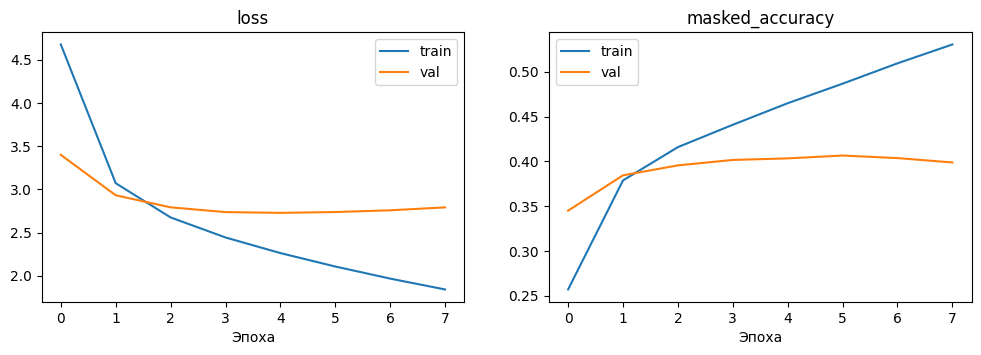

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for key, ax in zip(["loss", "masked_accuracy"], axes):
    ax.plot(history.history[key], label="train"); ax.plot(history.history[f"val_{key}"], label="val")
    ax.set_title(key); ax.set_xlabel("Эпоха"); ax.legend()
plt.show()

## 6. Генерация описаний

Описание порождается жадно: начиная с `<start>`, на каждом шаге добавляется самое вероятное слово,
пока не будет сгенерирован `<end>` или не достигнута максимальная длина. Декодирование выполняется
сразу для пакета изображений.

In [9]:
def generate(feats):
    seqs = np.full((len(feats), 1), START, dtype="int32")
    done = np.zeros(len(feats), bool)
    for _ in range(MAX_LEN - 1):
        logits = model.predict_on_batch([feats, seqs])[:, -1]
        logits[:, [PAD, UNK, START]] = -1e9
        nxt = np.where(done, PAD, logits.argmax(-1)).astype("int32")
        seqs = np.concatenate([seqs, nxt[:, None]], axis=1)
        done |= nxt == END
        if done.all():
            break
    return [decode(s) for s in seqs]


test_names = splits["test"]
test_feats = features[[feat_index[n] for n in test_names]].astype("float32")
start = time.time()
test_preds = [c for i in range(0, len(test_feats), 250) for c in generate(test_feats[i:i + 250])]
print(f"Сгенерировано {len(test_preds)} описаний за {time.time() - start:.0f} с")

C:\Interpetetor\Lib\site-packages\keras\src\ops\nn.py:938: UserWarning: You are using a softmax over axis 3 of a tensor of shape (250, 4, 1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


Сгенерировано 1000 описаний за 16 с


## 7. Оценка BLEU

BLEU-n — среднее геометрическое точностей совпадения n-грамм (1…n) сгенерированного описания с
пятью эталонными, умноженное на штраф за краткость. Считается по корпусу (как в `nltk.corpus_bleu`).

In [10]:
def corpus_bleu(references, hypotheses, n_max=4):
    matches, totals = np.zeros(n_max), np.zeros(n_max)
    hyp_len = ref_len = 0
    for refs, hyp in zip(references, hypotheses):
        hyp, refs = hyp.split(), [r.split() for r in refs]
        hyp_len += len(hyp)
        ref_len += min((abs(len(r) - len(hyp)), len(r)) for r in refs)[1]
        for n in range(1, n_max + 1):
            h = collections.Counter(tuple(hyp[i:i + n]) for i in range(len(hyp) - n + 1))
            max_ref = collections.Counter()
            for r in refs:
                max_ref |= collections.Counter(tuple(r[i:i + n]) for i in range(len(r) - n + 1))
            matches[n - 1] += sum(min(c, max_ref[g]) for g, c in h.items())
            totals[n - 1] += max(len(hyp) - n + 1, 0)
    bp = 1.0 if hyp_len > ref_len else math.exp(1 - ref_len / max(hyp_len, 1))
    precisions = matches / np.maximum(totals, 1)
    return {f"BLEU-{n}": bp * math.exp(np.mean(np.log(np.maximum(precisions[:n], 1e-12)))) for n in range(1, n_max + 1)}


refs = [captions[n] for n in test_names]
scores = {"Наша модель": corpus_bleu(refs, test_preds)}

# Ориентир снизу: для каждого изображения выдаётся одно и то же самое частое описание обучающей выборки
most_common = collections.Counter(c for n in splits["train"] for c in captions[n]).most_common(1)[0][0]
scores[f"Константа «{most_common}»"] = corpus_bleu(refs, [most_common] * len(refs))
pd.DataFrame(scores).T.round(4)

,BLEU-1,BLEU-2,BLEU-3,BLEU-4
Наша модель,0.6136,0.4238,0.2829,0.1868
Константа «a dog runs through the grass»,0.3108,0.1274,0.0501,0.0240


Для сравнения: в статье Show, Attend and Tell (Xu et al., 2015) на Flickr8k получено BLEU-1 = 0.67,
BLEU-4 = 0.21 (с вниманием и beam search).

## 8. Примеры

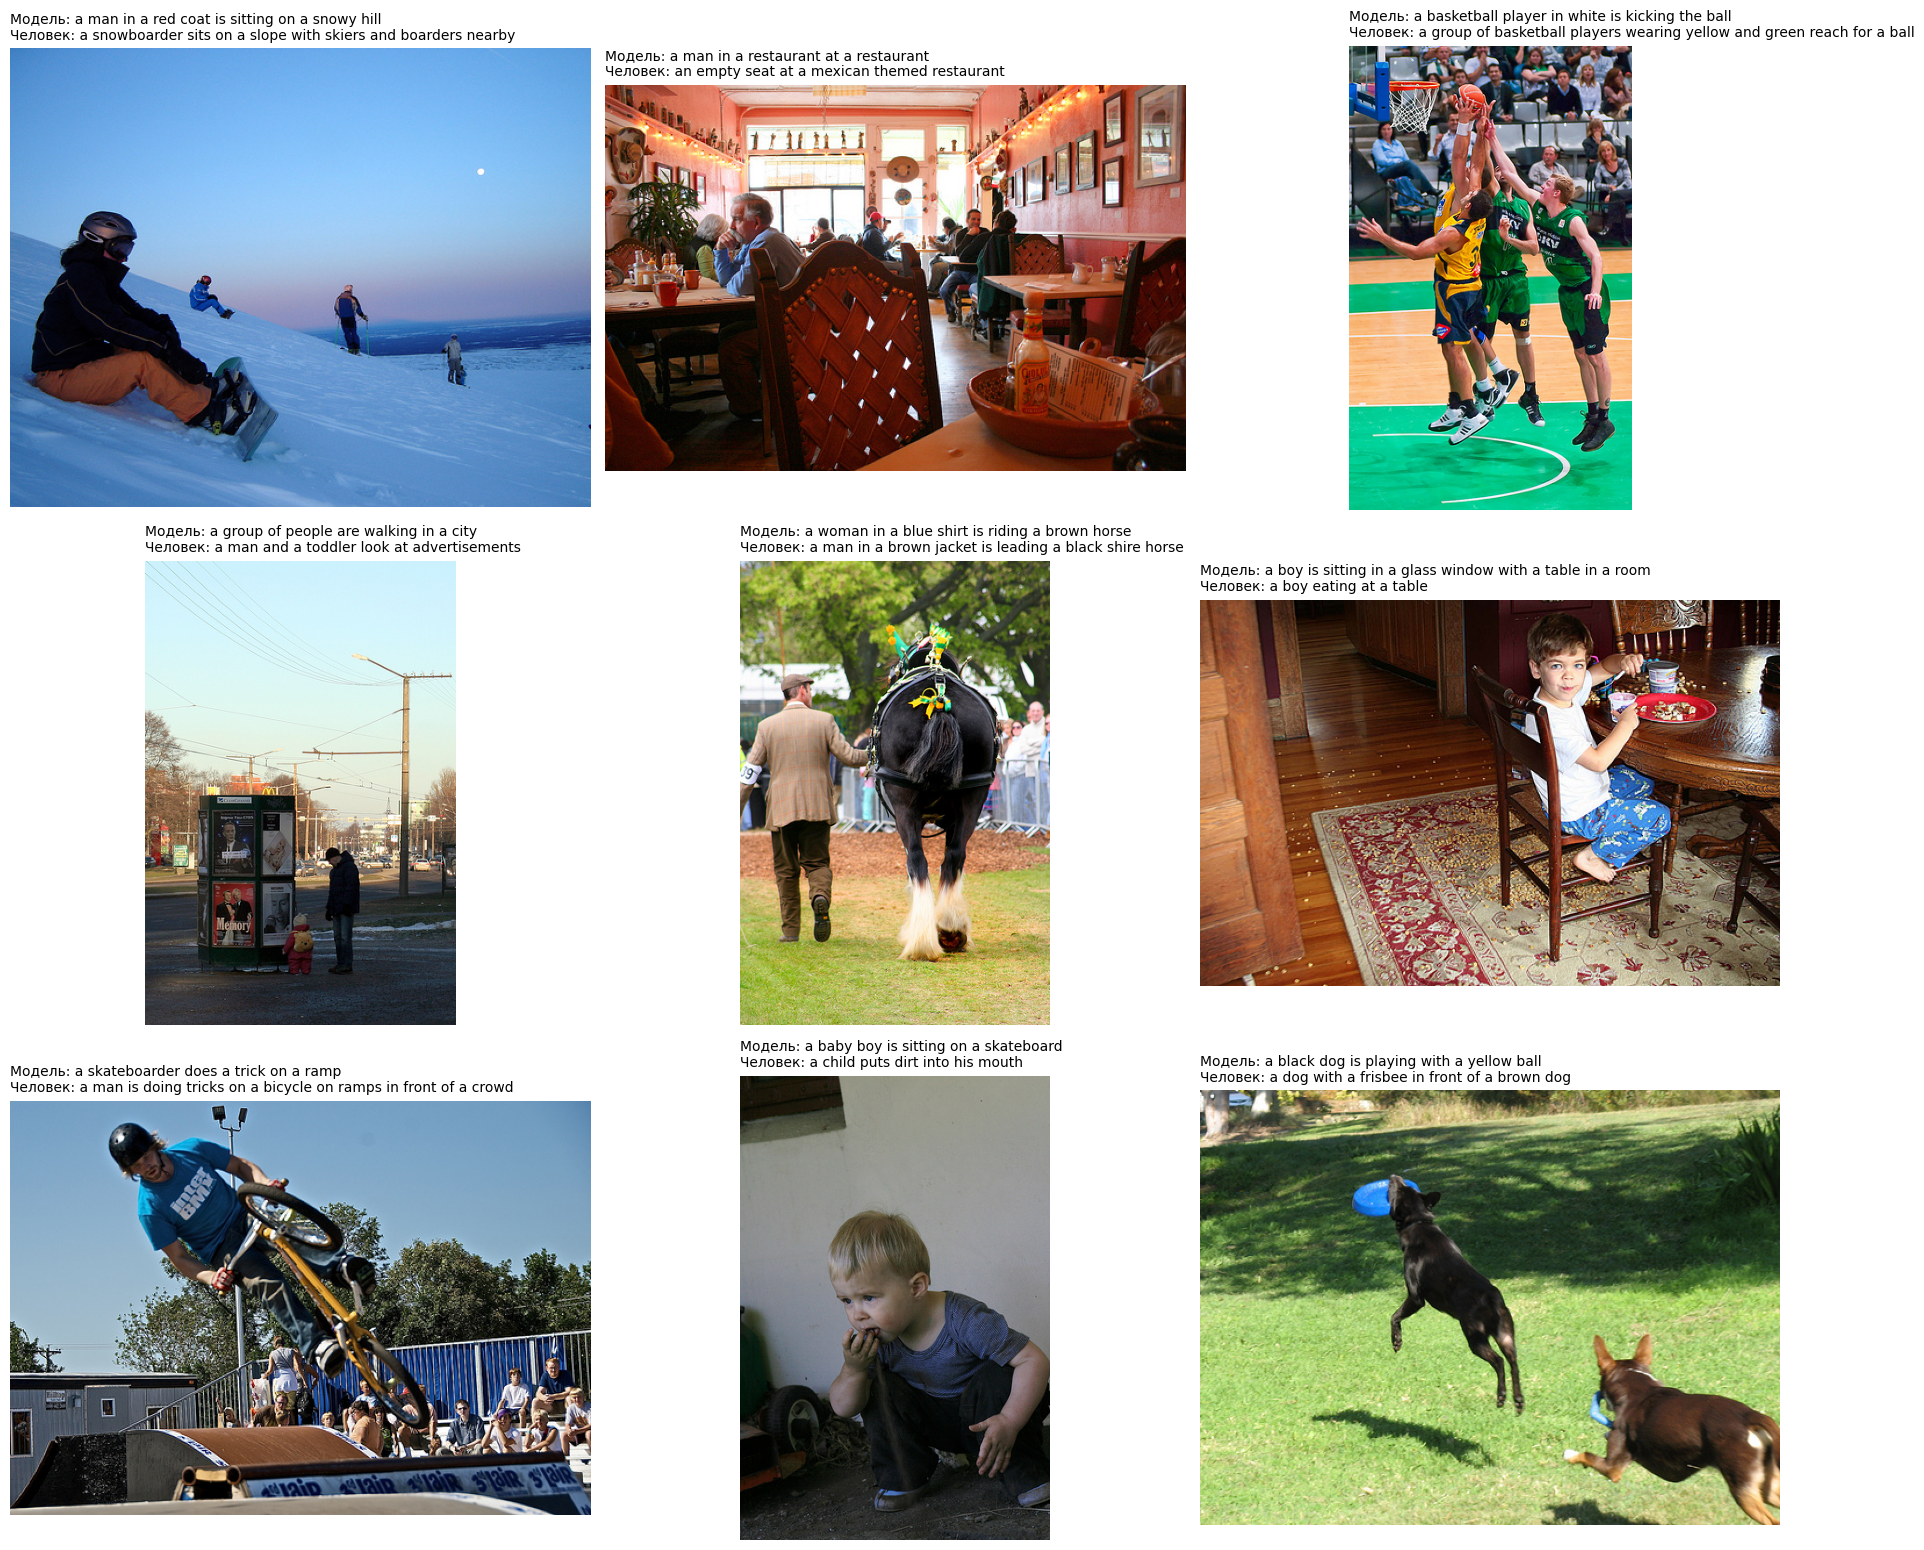

In [11]:
def show_examples(names, preds, cols=3):
    rows = math.ceil(len(names) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 5.2 * rows))
    for ax, n, p in zip(axes.ravel(), names, preds):
        ax.imshow(Image.open(os.path.join(IMG_DIR, n)))
        ax.set_title(f"Модель: {p}\nЧеловек: {captions[n][0]}", fontsize=10, loc="left")
        ax.axis("off")
    for ax in axes.ravel()[len(names):]:
        ax.axis("off")
    plt.tight_layout(); plt.show()


sample = list(np.random.default_rng(0).choice(len(test_names), 9, replace=False))
show_examples([test_names[i] for i in sample], [test_preds[i] for i in sample])

Разнообразие словаря: сколько разных описаний и слов модель использует на тесте.

In [12]:
words = collections.Counter(w for p in test_preds for w in p.split())
print(f"Уникальных описаний: {len(set(test_preds))} из {len(test_preds)}; уникальных слов: {len(words)}")
print("Самые частые слова:", words.most_common(15))

Уникальных описаний: 912 из 1000; уникальных слов: 434
Самые частые слова: [('a', 2133), ('is', 666), ('in', 583), ('on', 273), ('the', 233), ('man', 219), ('dog', 190), ('of', 183), ('and', 175), ('with', 169), ('shirt', 168), ('standing', 160), ('black', 159), ('are', 156), ('white', 145)]


## 9. Применение к произвольному изображению

Функция `caption_image` принимает путь к изображению (`.png`, `.bmp`, `.jpg`) и возвращает описание.

In [13]:
def caption_image(path):
    img = Image.open(path).convert("RGB").resize((299, 299), Image.BICUBIC)
    x = tf.keras.applications.inception_v3.preprocess_input(np.asarray(img, dtype="float32"))[None]
    feats = encoder_cnn(x, training=False).numpy().reshape(1, 16, 2048)
    return generate(feats)[0]


example = os.path.join(IMG_DIR, test_names[1])
Image.open(example).convert("RGB").resize((160, 120)).save("example_input.bmp")  # низкое разрешение, BMP
print("example_input.bmp →", caption_image("example_input.bmp"))

example_input.bmp → two children are playing in a pool


## Выводы

* Модель «замороженный CNN-энкодер + трансформер-декодер» за 8 эпох (≈28 минут на CPU, лучшая — 5-я) научилась
  порождать грамматически корректные описания: BLEU-1 = 0.61, BLEU-4 = 0.19 на тестовой выборке
  Flickr8k — близко к результату Show, Attend and Tell (0.67 / 0.21), который использует beam search.
  Константное описание даёт лишь BLEU-4 = 0.02, т.е. модель действительно опирается на изображение.
* Модель хорошо распознаёт основные сцены и объекты (снег, баскетбол, лошадь, собака с мячом, рампа),
  но ошибается в деталях: путает похожие действия и предметы (велосипед ↔ скейтборд, фрисби ↔ мяч),
  пол и количество людей, иногда повторяет слова («in a restaurant at a restaurant»).
* После 5-й эпохи начинается переобучение (val_loss растёт при падении train loss), поэтому ранняя
  остановка вернула веса лучшей эпохи. 30 тыс. описаний — мало для трансформера; описания используют
  всего ≈430 разных слов из 2533 в словаре — модель предпочитает частые формулировки.
* Улучшения: beam search вместо жадного декодирования, дообучение энкодера, ViT-энкодер и
  предсказание семантических концептов как в ViTCAP, датасеты большего размера (COCO, Flickr30k).